# 34. Convolutional NNs IV: Plastic Waste Classification

Shengli (Bruce) Jiang, University of South Carolina

Keep the `data/plasticnet/` folder beside this notebook. 

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

In [2]:
NAVY = '#17233F'
RED = '#8E0B19'
np.set_printoptions(precision=3, suppress=True)
plt.style.use('default')
plt.rcParams.update({
    'font.size': 11,
    'text.color': 'black',
    'axes.titlecolor': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'legend.labelcolor': 'black',
    'figure.dpi': 120,
})

## PlasticNet Spectra

Each row is one ATR-FTIR scan with 4150 absorbance readings from 2000 to 4000 cm⁻¹. There are 70 scans for each of 10 plastics. [Jiang et al. (2021)](https://doi.org/10.1016/j.compchemeng.2021.107547)

In [3]:
data = np.load('data/plasticnet/plasticnet.npz')
spectra = data['spectra']
y = data['labels']
classes = data['classes']
wavenumber = data['wavenumber']
print('Spectra:', spectra.shape)
print('Labels:', y.shape)

Spectra: (700, 4150)
Labels: (700,)


In [4]:
print(classes)
print(np.bincount(y))

['ABS' 'AC' 'PE' 'PET' 'PB' 'PC' 'PI' 'PS' 'PP' 'PVC']
[70 70 70 70 70 70 70 70 70 70]


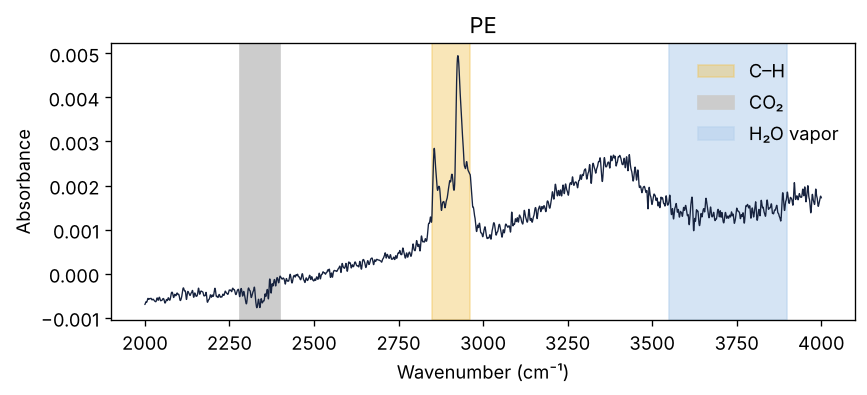

In [5]:
pe = np.flatnonzero(y == 2)[0]  # first PE scan

plt.figure(figsize=(8, 3))
plt.plot(wavenumber, spectra[pe], color=NAVY, lw=0.8)
plt.axvspan(2850, 2960, color='#F2C14E', alpha=0.4, label='C–H')
plt.axvspan(2280, 2400, color='0.8', label='CO₂')
plt.axvspan(3550, 3900, color='#B9D3EE', alpha=0.6, label='H₂O vapor')
plt.xlabel('Wavenumber (cm⁻¹)')
plt.ylabel('Absorbance')
plt.title('PE')
plt.legend(frameon=False)
plt.show()

Scans of the same plastic differ in baseline offset, slope, and noise.

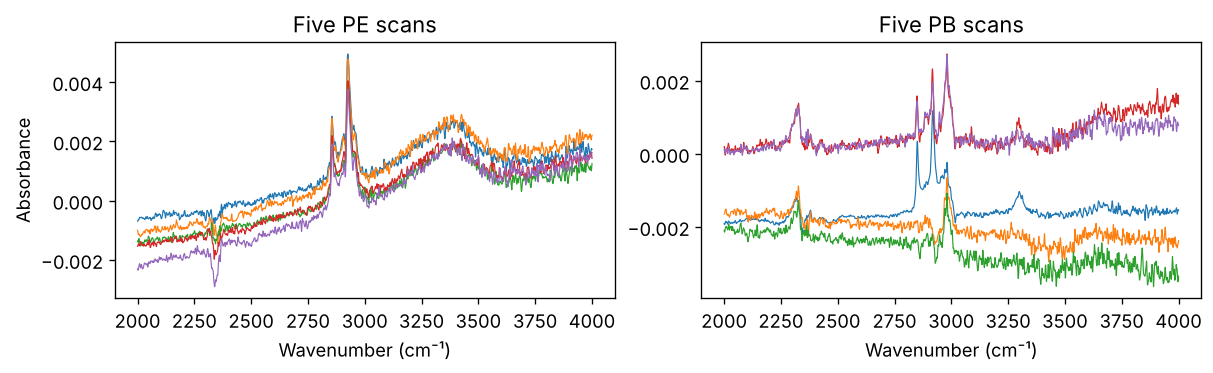

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout='constrained')
for ax, k in zip(axes, [2, 4]):
    for i in np.flatnonzero(y == k)[:5]:
        ax.plot(wavenumber, spectra[i], lw=0.7)
    ax.set(title=f'Five {classes[k]} scans', xlabel='Wavenumber (cm⁻¹)')
axes[0].set_ylabel('Absorbance')
plt.show()

## Binning

Average neighboring readings into `n_bins` bins. With 200 bins, each bin averages about 21 readings, or 10 cm⁻¹. Start with the PE scan.

In [7]:
n_bins = 200
groups = np.array_split(spectra[pe], n_bins)
print('Number of bins:', len(groups))
print('Readings in the first bin:', len(groups[0]))

Number of bins: 200
Readings in the first bin: 21


In [8]:
pe_bins = np.array([g.mean() for g in groups])
wn_bins = np.array([g.mean() for g in np.array_split(wavenumber, n_bins)])
pe_bins.shape

(200,)

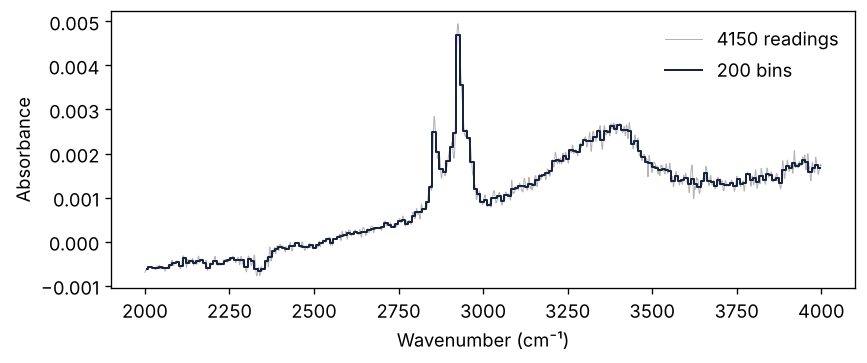

In [9]:
plt.figure(figsize=(8, 3))
plt.plot(wavenumber, spectra[pe], color='0.7', lw=0.6, label='4150 readings')
plt.step(wn_bins, pe_bins, where='mid', color=NAVY, lw=1.2, label=f'{n_bins} bins')
plt.xlabel('Wavenumber (cm⁻¹)')
plt.ylabel('Absorbance')
plt.legend(frameon=False)
plt.show()

Scale the binned scan to $[0, 1]$ with its own minimum and maximum.

In [10]:
x = (pe_bins - pe_bins.min()) / (pe_bins.max() - pe_bins.min())
x.min(), x.max()

(np.float32(0.0), np.float32(1.0))

Apply both steps to all 700 scans. `axis=1` splits along the readings, and `keepdims=True` gives one minimum and maximum per scan.

In [11]:
bins = np.column_stack([g.mean(axis=1) for g in np.array_split(spectra, n_bins, axis=1)])
lo = bins.min(axis=1, keepdims=True)
hi = bins.max(axis=1, keepdims=True)
bins = (bins - lo) / (hi - lo)
bins.shape

(700, 200)

## Gramian Angular Fields

Map each scaled bin to an angle $\phi_i = \arccos x_i$. Pixel $(i, j)$ of the GASF stores $\cos(\phi_i + \phi_j)$, and pixel $(i, j)$ of the GADF stores $\sin(\phi_i - \phi_j)$. Start with three bins.

In [12]:
toy = np.array([0, 0.5, 1])
phi = np.arccos(toy)
np.degrees(phi)

array([90., 60.,  0.])

`phi[:, None] + phi[None, :]` adds every pair of angles. Entry (0, 1) is cos 150° = −0.87.

In [13]:
np.cos(phi[:, None] + phi[None, :]).round(2)

array([[-1.  , -0.87,  0.  ],
       [-0.87, -0.5 ,  0.5 ],
       [ 0.  ,  0.5 ,  1.  ]])

In [14]:
np.sin(phi[:, None] - phi[None, :]).round(2)

array([[ 0.  ,  0.5 ,  1.  ],
       [-0.5 ,  0.  ,  0.87],
       [-1.  , -0.87,  0.  ]])

The GASF is symmetric, and its diagonal $\cos 2\phi_i = 2x_i^2 - 1$ keeps the spectrum. The GADF is antisymmetric with a zero diagonal.

Now the PE scan.

In [15]:
phi = np.arccos(x)
pe_gasf = np.cos(phi[:, None] + phi[None, :])
pe_gadf = np.sin(phi[:, None] - phi[None, :])
pe_gasf.shape, pe_gadf.shape

((200, 200), (200, 200))

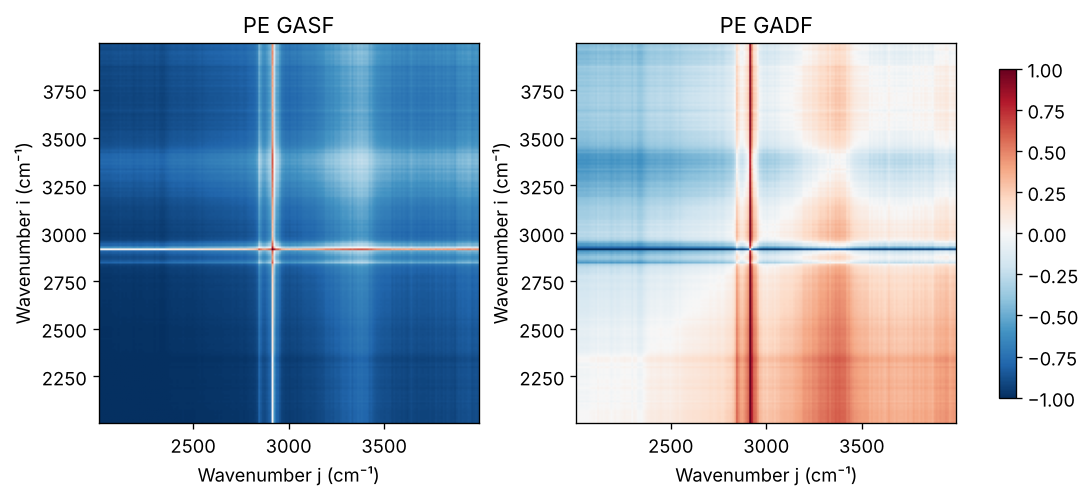

In [16]:
extent = (wn_bins[0], wn_bins[-1], wn_bins[0], wn_bins[-1])
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
for ax, field, title in zip(axes, [pe_gasf, pe_gadf], ['GASF', 'GADF']):
    im = ax.imshow(field, origin='lower', cmap='RdBu_r', vmin=-1, vmax=1, extent=extent)
    ax.set(title=f'PE {title}', xlabel='Wavenumber j (cm⁻¹)', ylabel='Wavenumber i (cm⁻¹)')
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

Pixel (2920, 2350) pairs the C–H band with the CO₂ band, so a 3 × 3 filter compares two distant regions in its first layer.

For all scans, the middle two axes pair bin $i$ with bin $j$, and the last axis holds the two channels.

In [17]:
phi = np.arccos(bins).astype('float32')
gasf = np.cos(phi[:, :, None] + phi[:, None, :])
gadf = np.sin(phi[:, :, None] - phi[:, None, :])
X_2d = np.stack([gasf, gadf], axis=-1)
X_1d = bins[..., None].astype('float32')
print('1D input:', X_1d.shape)
print('2D input:', X_2d.shape, f'{X_2d.nbytes / 1e6:.0f} MB')

1D input: (700, 200, 1)
2D input: (700, 200, 200, 2) 224 MB


## Training, Validation, and Test Sets

Hold out 20% for testing, then split the rest 70/30 into training and validation. `stratify` keeps the ten plastics balanced in every set.

In [18]:
from sklearn.model_selection import train_test_split

seed = 42
idx = np.arange(len(y))
train_val, test = train_test_split(idx, test_size=0.2, stratify=y, random_state=seed)
train, val = train_test_split(train_val, test_size=0.3, stratify=y[train_val], random_state=seed)
len(train), len(val), len(test)

(392, 168, 140)

In [19]:
np.bincount(y[test])

array([14, 14, 14, 14, 14, 14, 14, 14, 14, 14])

## 1D CNN

Each Conv1D filter spans three neighboring bins. Two pooling layers shrink 200 bins to 50 before the dense layers.

In [20]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(seed)
cnn_1d = keras.Sequential([
    keras.Input(shape=(n_bins, 1)),
    layers.Conv1D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(len(classes), activation='softmax'),
], name='cnn_1d')
cnn_1d.summary()

Model: "cnn_1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 200, 16)        │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 100, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 100, 32)        │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 50, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        51,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,194 (207.79 KB)

 Trainable params: 53,194 (207.79 KB)

 Non-trainable params: 0 (0.00 B)

Early stopping keeps the weights with the lowest validation loss.

In [21]:
cnn_1d.compile(optimizer=keras.optimizers.Adam(0.001),
               loss='sparse_categorical_crossentropy', metrics=['accuracy'])
stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
history_1d = cnn_1d.fit(X_1d[train], y[train], validation_data=(X_1d[val], y[val]),
                        epochs=100, batch_size=32, callbacks=[stop], verbose=0)
print('Best epoch:', np.argmin(history_1d.history['val_loss']) + 1)

Best epoch: 52


## 2D CNN

The same blocks with 3 × 3 filters on the 200 × 200 × 2 fields. The second pool of 5 shrinks the map to 20 × 20. Training takes about a minute on a laptop CPU.

In [22]:
keras.utils.set_random_seed(seed)
cnn_2d = keras.Sequential([
    keras.Input(shape=(n_bins, n_bins, 2)),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(2),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(5),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(len(classes), activation='softmax'),
], name='cnn_2d')
cnn_2d.summary()

Model: "cnn_2d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 16)   │           304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       409,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 414,906 (1.58 MB)

 Trainable params: 414,906 (1.58 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
cnn_2d.compile(optimizer=keras.optimizers.Adam(0.001),
               loss='sparse_categorical_crossentropy', metrics=['accuracy'])
stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
history_2d = cnn_2d.fit(X_2d[train], y[train], validation_data=(X_2d[val], y[val]),
                        epochs=100, batch_size=32, callbacks=[stop], verbose=0)
print('Best epoch:', np.argmin(history_2d.history['val_loss']) + 1)

Best epoch: 25


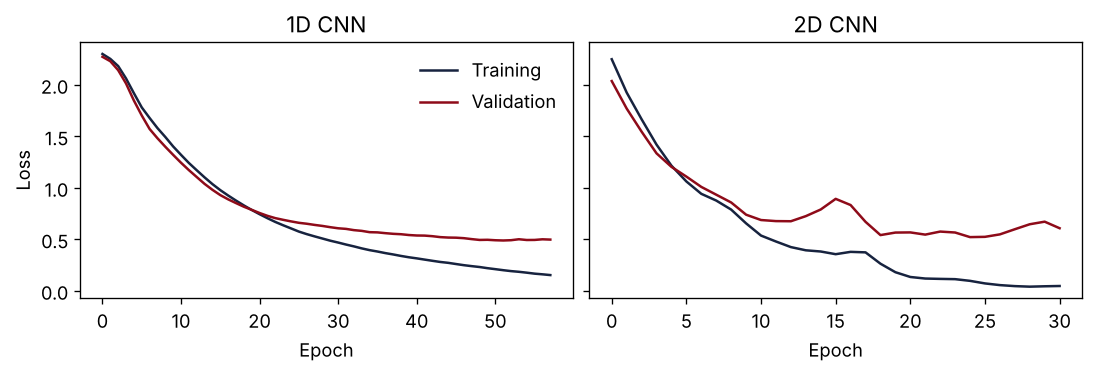

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout='constrained', sharey=True)
for ax, h, title in zip(axes, [history_1d, history_2d], ['1D CNN', '2D CNN']):
    ax.plot(h.history['loss'], color=NAVY, label='Training')
    ax.plot(h.history['val_loss'], color=RED, label='Validation')
    ax.set(title=title, xlabel='Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend(frameon=False)
plt.show()

## Test Results

Macro-F1 averages the F1 score over the ten plastics.

In [25]:
from sklearn.metrics import accuracy_score, f1_score

pred_1d = cnn_1d.predict(X_1d[test], verbose=0).argmax(axis=1)
pred_2d = cnn_2d.predict(X_2d[test], verbose=0).argmax(axis=1)
for name, model, pred in [('1D CNN', cnn_1d, pred_1d), ('2D CNN', cnn_2d, pred_2d)]:
    acc = accuracy_score(y[test], pred)
    f1 = f1_score(y[test], pred, average='macro')
    print(f'{name}: {model.count_params():>7,} parameters | accuracy {acc:.1%} | macro-F1 {f1:.3f}')

1D CNN:  53,194 parameters | accuracy 82.1% | macro-F1 0.813
2D CNN: 414,906 parameters | accuracy 83.6% | macro-F1 0.831


Recall is the fraction of the 14 test scans of each plastic that the model finds. One scan is 7 points of recall.

In [26]:
from sklearn.metrics import recall_score

recall_1d = recall_score(y[test], pred_1d, average=None)
recall_2d = recall_score(y[test], pred_2d, average=None)
print(f'{"":5}{"1D":>6}{"2D":>6}')
for name, r1, r2 in zip(classes, recall_1d, recall_2d):
    print(f'{name:5}{r1:6.2f}{r2:6.2f}')

         1D    2D
ABS    1.00  0.86
AC     0.86  0.79
PE     1.00  1.00
PET    0.79  0.79
PB     0.50  0.50
PC     0.43  0.79
PI     1.00  1.00
PS     0.93  1.00
PP     0.86  0.79
PVC    0.86  0.86


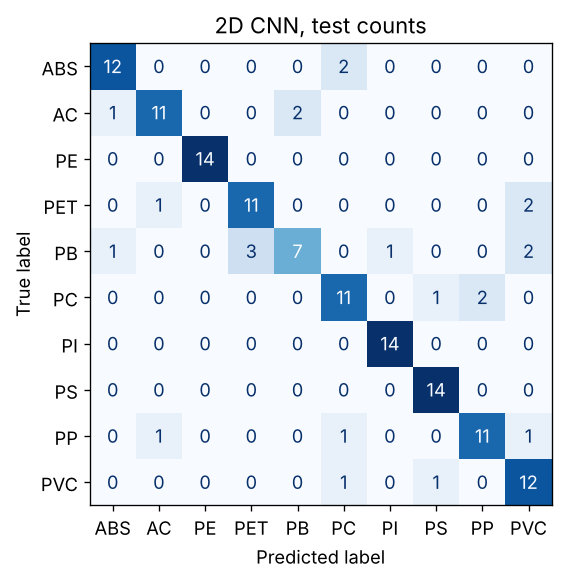

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(y[test], pred_2d, display_labels=classes,
                                        cmap='Blues', colorbar=False, ax=ax)
ax.set_title('2D CNN, test counts')
plt.show()